# LAB 4 — PHẦN E: HMM-BASED SPEECH SYNTHESIS (DEMO THAM SỐ)

**CSE457 – Xử lý âm thanh và tiếng nói** · Lab 4, mục **4.5**, **5.5** và kiến thức HMM phần **3.7**.

**Mục tiêu:** (1) ước lượng 3 state tuần tự từ các word-unit WAV thật ở bước A, (2) xây bảng state/transition và sinh F0, duration, spectral centroid theo frame, (3) trực quan hóa MLPG dùng static + delta features, (4) thử duration scale 0.8/1.2 và F0 scale 0.9/1.1, (5) giải thích HMM generation khác với concatenation.

> ⚠️ **Giới hạn khoa học:** Đây là **Gaussian left-to-right HMM parameter-generation demo** để quan sát, **không phải hệ HTS HMM-TTS đã huấn luyện EM/Baum–Welch hoặc vocoder**. Phân đoạn 3 state/word dùng chia đều theo thời gian, các phân bố được ước lượng từ các WAV có sẵn. **Không tạo `hmm_tts.wav`** vì chưa có bộ resynthesis từ tham số âm học. Điều này phù hợp với lưu ý ở trang 7: quan sát HMM trajectory, không bắt buộc tái tổng hợp waveform từ MFCC.

## 0. Thư mục và môi trường

Đặt `Lab04_Buoc5_E.ipynb` và **`hmm_tts_backend.py`** cùng cấp trong folder `Lab04_TTS`:

```text
Lab04_TTS/
├── Lab04_Buoc5_E.ipynb
├── hmm_tts_backend.py
├── lab4_data/
│   └── units/
│       ├── moi_01.wav  moi_02.wav ...
│       ├── ba_01.wav   ba_02.wav  ...
│       └── ...
├── audio_output/
│   ├── raw_concat.wav
│   └── best_concat.wav
├── figures/
└── hmm_output/                 ← notebook tạo tự động
```

Mở VS Code → chọn Kernel đã chạy A–D. Nếu thiếu gói:

```powershell
python -m pip install numpy scipy pandas matplotlib librosa soundfile ipython
```

**Không cần tải thêm pretrained model**, không cần huấn luyện GPU, không cần tạo Conda environment mới.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import hmm_tts_backend as hmm

ROOT = Path.cwd().resolve()
UNIT_DIR = ROOT / 'lab4_data' / 'units'
E_DIR = ROOT / 'hmm_output'
FIG_DIR = ROOT / 'figures'
E_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

TEXT = 'Mời khách hàng số 23 đến quầy 5.'
TOKENS = hmm.normalize_queue_text(TEXT)
print('Normalized tokens:', TOKENS)
print('Inventory directory:', UNIT_DIR)
for token in dict.fromkeys(TOKENS):
    paths = hmm.locate_candidates(UNIT_DIR,token)
    print(f'  {token:<7} {len(paths)} candidate(s): {[p.name for p in paths]}')
    if not paths:
        raise FileNotFoundError(f'Không có WAV cho {token!r} trong {UNIT_DIR}. Chạy phần A trước.')

Normalized tokens: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']
Inventory directory: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\lab4_data\units
  mời     2 candidate(s): ['moi_01.wav', 'moi_02.wav']
  khách   2 candidate(s): ['khach_01.wav', 'khach_02.wav']
  hàng    2 candidate(s): ['hang_01.wav', 'hang_02.wav']
  số      2 candidate(s): ['so_01.wav', 'so_02.wav']
  hai     2 candidate(s): ['hai_01.wav', 'hai_02.wav']
  ba      2 candidate(s): ['ba_01.wav', 'ba_02.wav']
  đến     2 candidate(s): ['den_01.wav', 'den_02.wav']
  quầy    2 candidate(s): ['quay_01.wav', 'quay_02.wav']
  năm     2 candidate(s): ['nam_01.wav', 'nam_02.wav']


## 1. Xây dựng model state-conditioned Gaussian từ audio có thật

Mỗi **word-unit** được chia thành 3 **state tuần tự** (đầu/giữa/cuối). Trên mỗi frame 10 ms, trích 3 tham số:

- `log(F0)`: ước lượng cao độ **frame có tính hữu thanh**; frame vô thanh được đánh dấu bằng bộ lọc heuristic.
- `log(RMS)`: năng lượng/độ mạnh tín hiệu.
- `log(spectral centroid)`: **tham số phổ**, **không phải formant F1/F2**.

Với mỗi state, ước lượng **Gaussian static** $(\mu_c,\sigma_c^2)$ và **Gaussian delta** $(\mu_{\Delta c},\sigma_{\Delta c}^2)$. Xác suất tự lặp (`self-loop`) mang tính minh họa và được suy từ **thời lượng state trung bình**.

> Phân đoạn state cố định không phải học alignment HMM có giám sát/EM. Hai bản ghi/từ là rất ít, nên đây chỉ là mô hình minh họa phương pháp generation.

In [2]:
model = hmm.train_demo_model(UNIT_DIR, TOKENS, max_candidates=3)
print('Số word được sử dụng:', len(set(TOKENS)))
print('Số state ước lượng:', len(model['states']))
print('Số WAV được sử dụng:', len(model['unit_info']))
display(model['unit_info'])
model['unit_info'].to_csv(E_DIR/'e_training_units.csv',index=False,encoding='utf-8-sig')
transition = hmm.export_transition_table(model)
transition.to_csv(E_DIR/'e_hmm_transition_table.csv',index=False,encoding='utf-8-sig')
display(transition.head(12))

c:\Users\admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Số word được sử dụng: 9
Số state ước lượng: 27
Số WAV được sử dụng: 18


,word,candidate_file,duration_s,n_frames,voiced_fraction_heuristic
0,mời,moi_01.wav,0.500000,51,1.000000
1,mời,moi_02.wav,0.750000,76,0.407895
2,khách,khach_01.wav,0.625000,63,0.333333
3,khách,khach_02.wav,0.750000,76,0.223684
4,hàng,hang_01.wav,0.500000,51,0.941176
5,hàng,hang_02.wav,0.625000,63,0.396825
6,số,so_01.wav,0.625000,63,0.746032
7,số,so_02.wav,0.625000,63,0.634921
8,hai,hai_01.wav,0.500000,51,0.725490
9,hai,hai_02.wav,0.716000,72,0.416667


,word,state,transition_self_probability,transition_next_probability,avg_duration_frames,avg_duration_ms,trained_wav_count,training_frames
0,ba,1,0.967213,0.032787,30.5,305.0,2,61
1,ba,2,0.967213,0.032787,30.5,305.0,2,61
2,ba,3,0.966667,0.033333,30.0,300.0,2,60
3,hai,1,0.951220,0.048780,20.5,205.0,2,41
4,hai,2,0.951220,0.048780,20.5,205.0,2,41
5,hai,3,0.951220,0.048780,20.5,205.0,2,41
6,hàng,1,0.947368,0.052632,19.0,190.0,2,38
7,hàng,2,0.947368,0.052632,19.0,190.0,2,38
8,hàng,3,0.947368,0.052632,19.0,190.0,2,38
9,khách,1,0.957447,0.042553,23.5,235.0,2,47


## 2. Generation – sinh chuỗi state và trajectory tham số

Với câu sau khi normalize, state sequence là:

$\text{mời}_1\to\text{mời}_2\to\text{mời}_3\to\text{khách}_1\to\dots$

Số frame của state được thiết lập theo thời lượng trung bình từ dữ liệu thực (10 ms/frame). State điều khiển phân bố của các tham số âm học theo từng frame.

\[
\lambda=(A,B,\pi),\qquad \hat O=\arg\max_O P(O\mid\lambda,\text{state sequence}).
\]

`A` (bảng chuyển state) và `B` (Gaussian features) được ước lượng đơn giản từ recording, không dùng Baum–Welch. Đầu ra gồm `e_hmm_state_sequence.csv` và `e_hmm_tracks.csv`.

In [3]:
tracks, states = hmm.generate_tracks(model, TEXT, duration_scale=1.0,
                                      f0_scale=1.0, apply_delta=True)
tracks.to_csv(E_DIR/'e_hmm_tracks.csv',index=False,encoding='utf-8-sig')
states.to_csv(E_DIR/'e_hmm_state_sequence.csv',index=False,encoding='utf-8-sig')
print('Tổng frame:',len(tracks), 'Duration:', round(len(tracks)*hmm.HOP/hmm.SR,3),'s')
print('Số state instances:',len(states),'cho',len(TOKENS),'từ')
display(states.head(9))
display(tracks.head())

Tổng frame: 594 Duration: 5.94 s
Số state instances: 27 cho 9 từ


,word_position,word,state,frames,duration_s,self_transition,advance_transition,mean_f0_hz,mean_rms,mean_spectral_centroid_hz,voiced_probability
0,1,mời,1,22,0.22,0.953488,0.046512,102.493124,0.011492,1250.526288,0.418605
1,1,mời,2,21,0.21,0.952381,0.047619,97.812734,0.110413,1235.835268,1.000000
2,1,mời,3,21,0.21,0.952381,0.047619,95.049153,0.022915,1399.188048,0.523810
3,2,khách,1,24,0.24,0.957447,0.042553,153.097714,0.029838,1346.910858,0.191489
4,2,khách,2,23,0.23,0.956522,0.043478,157.275129,0.050695,1329.024773,0.478261
5,2,khách,3,23,0.23,0.956522,0.043478,147.979949,0.020391,1147.632103,0.152174
6,3,hàng,1,19,0.19,0.947368,0.052632,104.837286,0.015507,1455.496703,0.500000
7,3,hàng,2,19,0.19,0.947368,0.052632,96.993731,0.097593,1277.289956,0.973684
8,3,hàng,3,19,0.19,0.947368,0.052632,94.426405,0.019210,1210.188418,0.447368


,time_s,word_position,word,state,f0_hz,f0_unmasked_hz,rms_amplitude,spectral_centroid_hz,raw_state_f0_hz,raw_state_rms,raw_state_centroid_hz,voiced_probability
0,0.00,1,mời,1,102.500078,102.500078,0.007839,1334.791351,102.493124,0.011492,1250.526288,0.418605
1,0.01,1,mời,1,102.491972,102.491972,0.008486,1308.961054,102.493124,0.011492,1250.526288,0.418605
2,0.02,1,mời,1,102.478993,102.478993,0.009060,1297.307027,102.493124,0.011492,1250.526288,0.418605
3,0.03,1,mời,1,102.477639,102.477639,0.009662,1282.867403,102.493124,0.011492,1250.526288,0.418605
4,0.04,1,mời,1,102.454865,102.454865,0.010279,1276.413222,102.493124,0.011492,1250.526288,0.418605


## 3. Vẽ HMM F0 contour và spectral parameter trajectory

Cần ít nhất **F0 contour** và **một spectral/formant parameter**. Ta chọn **spectral centroid** – đặc trưng phổ tính từ WAV; không gọi nhầm là formant.

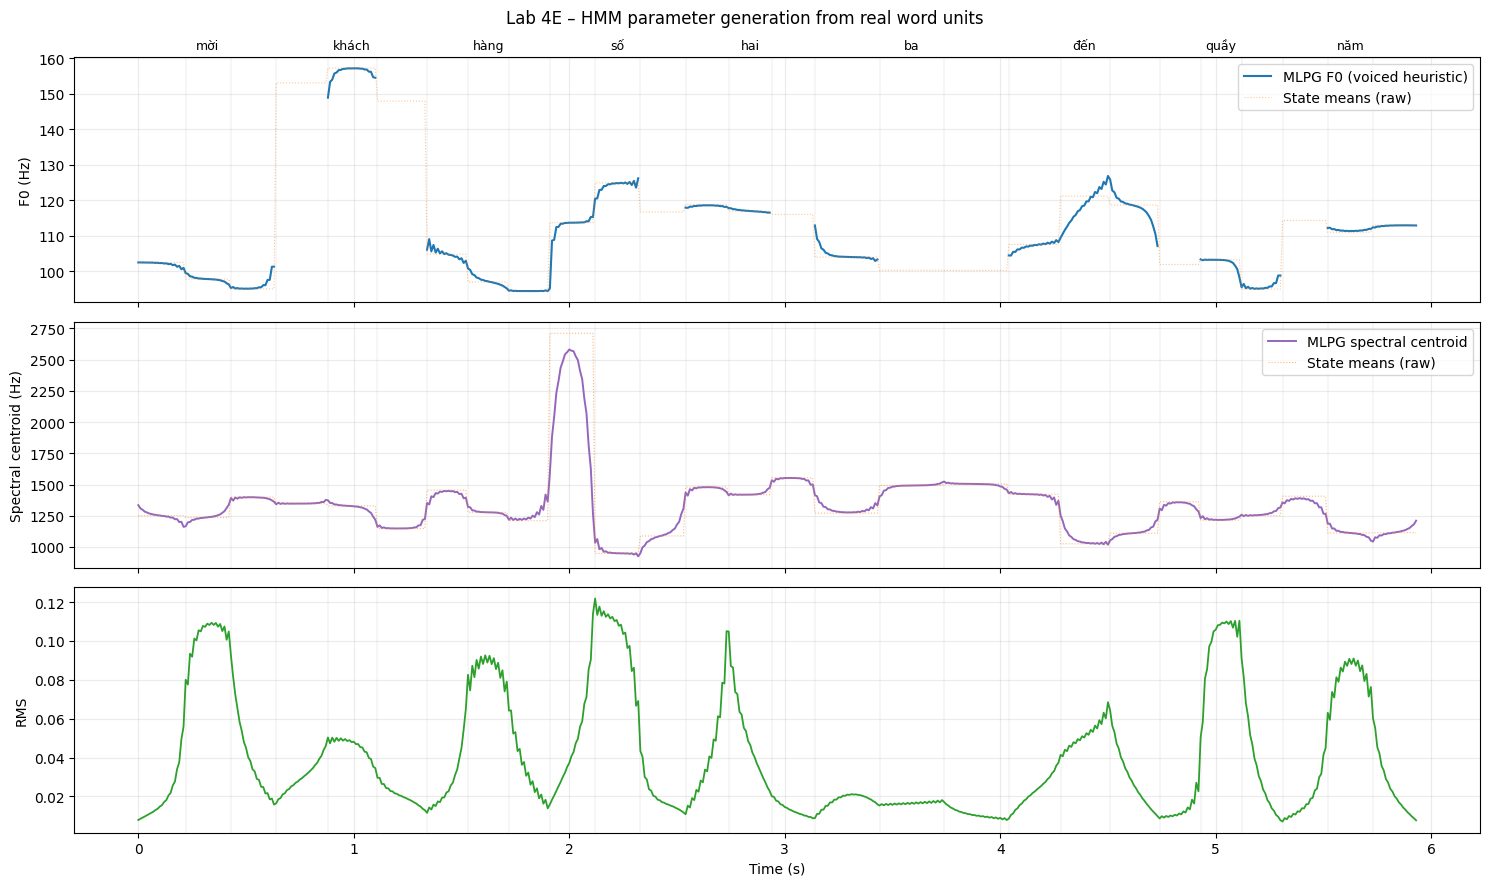

In [4]:
from matplotlib.patches import Patch

boundaries = np.cumsum(states['frames'].to_numpy()) * hmm.HOP / hmm.SR
fig,axes=plt.subplots(3,1,figsize=(15,9),sharex=True)
t=tracks['time_s'].to_numpy()
axes[0].plot(t,tracks['f0_hz'],lw=1.5,color='tab:blue',label='MLPG F0 (voiced heuristic)')
axes[0].plot(t,tracks['raw_state_f0_hz'],lw=.8,ls=':',alpha=.45,color='tab:orange',label='State means (raw)')
axes[0].set_ylabel('F0 (Hz)');axes[0].legend(loc='upper right')
axes[1].plot(t,tracks['spectral_centroid_hz'],lw=1.4,color='tab:purple',label='MLPG spectral centroid')
axes[1].plot(t,tracks['raw_state_centroid_hz'],ls=':',lw=.8,alpha=.55,color='tab:orange',label='State means (raw)')
axes[1].set_ylabel('Spectral centroid (Hz)');axes[1].legend(loc='upper right')
axes[2].plot(t,tracks['rms_amplitude'],lw=1.3,color='tab:green')
axes[2].set_ylabel('RMS');axes[2].set_xlabel('Time (s)')
for ax in axes:
    ax.grid(alpha=.25)
    for b in boundaries[:-1]: ax.axvline(b,lw=.32,alpha=.3,color='gray')
# Labels at word centers, not every state
cursor=0
for pos,subset in states.groupby('word_position',sort=False):
    f=subset['frames'].sum()
    center=(cursor+f/2)*hmm.HOP/hmm.SR
    axes[0].text(center,1.02,TOKENS[int(pos)-1],ha='center',va='bottom',
                 transform=axes[0].get_xaxis_transform(),fontsize=9)
    cursor+=f
fig.suptitle('Lab 4E – HMM parameter generation from real word units')
fig.tight_layout(); fig.savefig(FIG_DIR/'e_hmm_f0_spectral_trajectory.png',dpi=180)
plt.show()

## 4. Delta-feature MLPG: trước và sau làm mượt

Trong demo, **maximum likelihood parameter generation (MLPG)** tìm trajectory tối ưu cho Gaussian static và delta. Với một chiều tham số, ta giải:

\[
\hat{\mathbf c}=\arg\min_{\mathbf c}\left[
\sum_t\frac{(c_t-\mu_t)^2}{\sigma_t^2}+
\lambda\sum_t\frac{(\Delta c_t-\mu_{\Delta,t})^2}{\sigma_{\Delta,t}^2}
\right].
\]

Delta liên kết các frame kề nhau nên có thể giảm sự thay đổi đột ngột. Điều này mô phỏng cơ chế **trajectory generation từ static+delta**, không chứng minh naturalness cao hơn nếu chưa có vocoder và listening test.

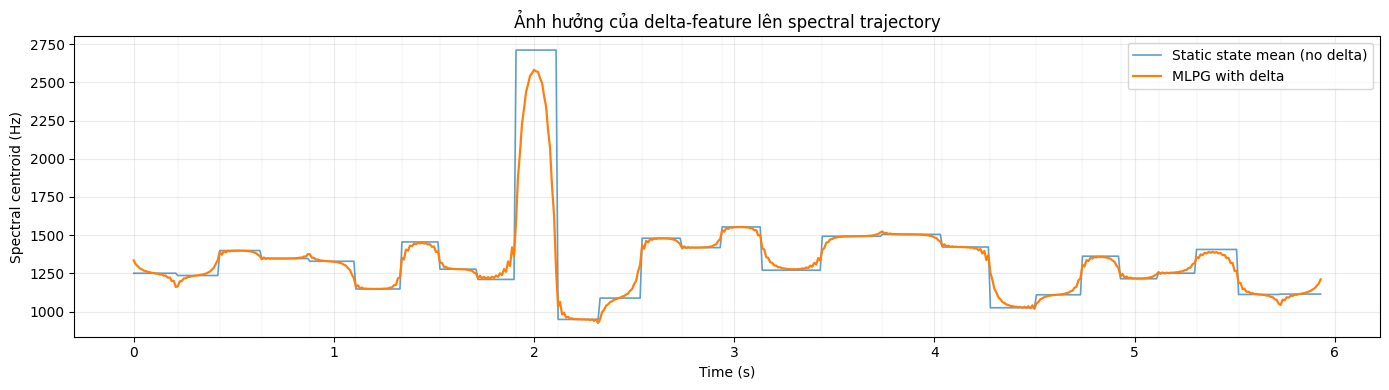

In [5]:
raw_tracks,_ = hmm.generate_tracks(model,TEXT,apply_delta=False)
fig,ax=plt.subplots(figsize=(14,4))
ax.plot(t,raw_tracks['spectral_centroid_hz'],label='Static state mean (no delta)',lw=1.2,alpha=.7)
ax.plot(t,tracks['spectral_centroid_hz'],label='MLPG with delta',lw=1.6)
for b in boundaries[:-1]: ax.axvline(b,color='gray',alpha=.2,lw=.3)
ax.set(xlabel='Time (s)',ylabel='Spectral centroid (Hz)',
       title='Ảnh hưởng của delta-feature lên spectral trajectory')
ax.grid(alpha=.25);ax.legend();fig.tight_layout()
fig.savefig(FIG_DIR/'e_hmm_delta_mlpg.png',dpi=180);plt.show()

## 5. Thử thay duration scale và F0 scale (không resynthesis waveform)

Mục 4.5 yêu cầu **thay một tham số**, ví dụ duration 0.8/1.2 hoặc F0 0.9/1.1, và **nghe audio nếu backend hỗ trợ**. Ta thử **cả hai** biến và so sánh định lượng; backend này chỉ sinh trajectory nên không có WAV để nghe. Kết quả không được gọi là "HMM TTS voice".

In [6]:
rows=[]; variants={}
for dscale,pscale in [(0.8,1.0),(1.0,1.0),(1.2,1.0),(1.0,0.9),(1.0,1.1)]:
    tr,ss=hmm.generate_tracks(model,TEXT,duration_scale=dscale,f0_scale=pscale)
    tag=f'dur_{dscale:.1f}_f0_{pscale:.1f}'.replace('.','p')
    variants[tag]=(tr,ss)
    tr.to_csv(E_DIR/f'e_hmm_{tag}_tracks.csv',index=False,encoding='utf-8-sig')
    finite=tr['f0_hz'].dropna()
    rows.append({'variant':tag,'duration_scale':dscale,'f0_scale':pscale,
        'duration_s':len(tr)*hmm.HOP/hmm.SR,
        'median_generated_f0_hz':float(finite.median()) if len(finite) else np.nan,
        'mean_spectral_centroid_hz':float(tr['spectral_centroid_hz'].mean()),
        'waveform_available':False})
variants_df=pd.DataFrame(rows)
variants_df.to_csv(E_DIR/'e_hmm_parameter_experiments.csv',index=False,encoding='utf-8-sig')
display(variants_df)

,variant,duration_scale,f0_scale,duration_s,median_generated_f0_hz,mean_spectral_centroid_hz,waveform_available
0,dur_0p8_f0_1p0,0.8,1.0,4.73,107.823223,1322.336259,False
1,dur_1p0_f0_1p0,1.0,1.0,5.94,107.633455,1325.045567,False
2,dur_1p2_f0_1p0,1.2,1.0,7.17,107.648961,1327.688032,False
3,dur_1p0_f0_0p9,1.0,0.9,5.94,96.870109,1325.045567,False
4,dur_1p0_f0_1p1,1.0,1.1,5.94,118.396800,1325.045567,False


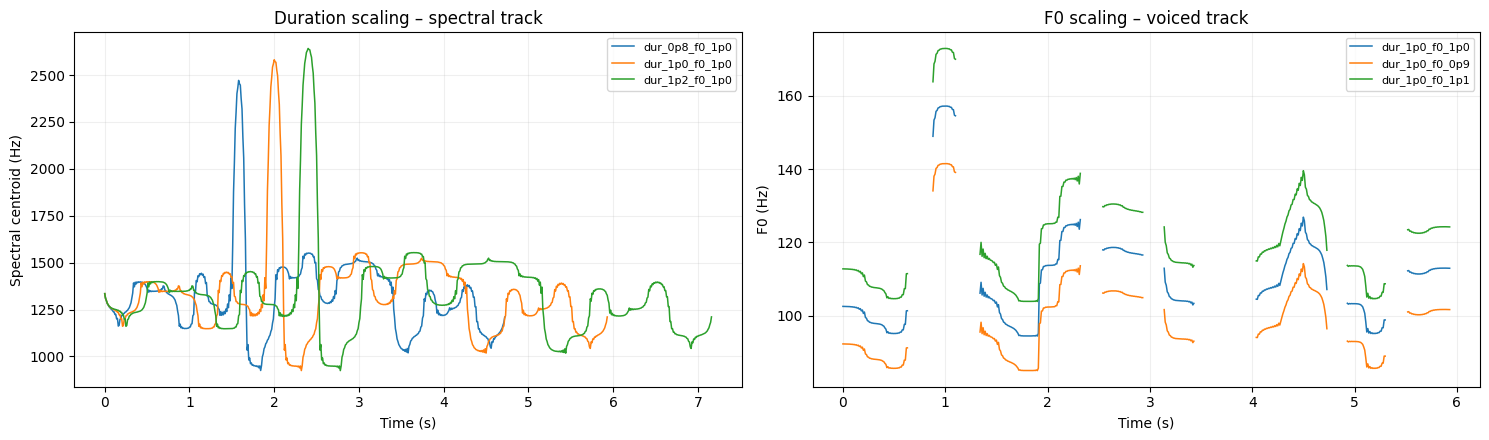

In [7]:
fig,axes=plt.subplots(1,2,figsize=(15,4.5))
for tag,(tr,ss) in variants.items():
    if 'f0_1p0' in tag:
        axes[0].plot(tr['time_s'],tr['spectral_centroid_hz'],label=tag,lw=1.1)
    if 'dur_1p0' in tag:
        axes[1].plot(tr['time_s'],tr['f0_hz'],label=tag,lw=1.1)
axes[0].set(xlabel='Time (s)',ylabel='Spectral centroid (Hz)',title='Duration scaling – spectral track')
axes[1].set(xlabel='Time (s)',ylabel='F0 (Hz)',title='F0 scaling – voiced track')
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG_DIR/'e_hmm_parameter_variants.png',dpi=180);plt.show()

## 6. Phân biệt HMM generation và waveform concatenation

| Tiêu chí | Ghép nối (Lab 4B–C) | HMM parameter demo (Lab 4E) |
|---|---|---|
| Đầu vào xử lý | Chọn WAV của từ đã ghi | Text → word → state sequence |
| Đại diện âm học | Toàn bộ waveform tự nhiên | Phân bố Gaussian của F0/RMS/centroid |
| Tạo đầu ra | Copy/cross-fade waveform | Sinh trajectories theo state, MLPG |
| Có WAV nghe được? | Có (`best_concat.wav`) | **Chưa**: thiếu vocoder/source-filter resynthesis |
| Hạn chế | Click/khác biệt giọng giữa unit | Không có waveform, state alignment còn sơ khai |

**Điểm nộp bắt buộc phần E:** 1) state sequence, 2) F0 + tham số phổ theo frame, 3) một thử nghiệm scale tham số, 4) giải thích khác nhau giữa hai cách tổng hợp.

**Không nên ghi trong báo cáo:** "đã huấn luyện hệ HMM TTS hoàn chỉnh" hoặc "đã phát sinh giọng nói từ HMM". Tên đúng: *data-conditioned Gaussian HMM parameter-generation demonstration*.

In [8]:
print('Các file đầu ra phần E:')
for file in sorted(E_DIR.glob('e_*.csv')):
    print(' ',file.relative_to(ROOT))
for file in sorted(FIG_DIR.glob('e_hmm_*.png')):
    print(' ',file.relative_to(ROOT))
assert len(states)==3*len(TOKENS)
assert tracks['time_s'].is_monotonic_increasing
assert (tracks['spectral_centroid_hz']>0).all()
print('CHECK: PASS — state, trajectory, units và outputs đều hợp lệ.')

Các file đầu ra phần E:
  hmm_output\e_hmm_dur_0p8_f0_1p0_tracks.csv
  hmm_output\e_hmm_dur_1p0_f0_0p9_tracks.csv
  hmm_output\e_hmm_dur_1p0_f0_1p0_tracks.csv
  hmm_output\e_hmm_dur_1p0_f0_1p1_tracks.csv
  hmm_output\e_hmm_dur_1p2_f0_1p0_tracks.csv
  hmm_output\e_hmm_parameter_experiments.csv
  hmm_output\e_hmm_state_sequence.csv
  hmm_output\e_hmm_tracks.csv
  hmm_output\e_hmm_transition_table.csv
  hmm_output\e_training_units.csv
  figures\e_hmm_delta_mlpg.png
  figures\e_hmm_f0_spectral_trajectory.png
  figures\e_hmm_parameter_variants.png
CHECK: PASS — state, trajectory, units và outputs đều hợp lệ.
